In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
path = "../data/online_retail_II.xlsx"
df1 = pd.read_excel(path, sheet_name="Year 2009-2010")
df2 = pd.read_excel(path, sheet_name="Year 2010-2011")
df = pd.concat([df1, df2], ignore_index=True)
print("Rows and columns:", df.shape)

Rows and columns: (1067371, 8)


In [3]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

In [5]:
# Check for missing values
df.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [6]:
# Show rows with missing values
df[df.isna().any(axis=1)].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,United Kingdom


In [7]:
# Check for duplicates
df.duplicated().sum()


np.int64(34335)

In [8]:
# Show duplicate rows
df[df.duplicated(keep=False)].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [9]:
# Show summary statistics for Quantity and Price columns
df[["Quantity", "Price"]].describe().round(2)

,Quantity,Price
count,1067371.00,1067371.00
mean,9.94,4.65
std,172.71,123.55
min,-80995.00,-53594.36
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,80995.00,38970.00


Quantity: The median is 3, while the mean is around 9.94. This suggests that some transactions have much larger quantities than others.

Price: The median price is 2.10, while the mean is 4.65.

Negative values: Both Quantity and Price contain negative values. These may be related to returns, cancellations, or data errors.

Extreme values: The maximum values are much higher than the median, so further investigation is needed.

In [10]:
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())

Quantity <= 0: 22950


In [11]:
print("Price <= 0:", (df["Price"] <= 0).sum())

Price <= 0: 6207


In [12]:
clean = df.copy()

In [13]:
clean = clean.drop_duplicates()
clean = clean.dropna(subset=["Customer ID"])

In [14]:
clean = clean[(clean["Quantity"] > 0) & (clean["Price"] > 0)].copy()

In [15]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 779425 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      779425 non-null  object        
 1   StockCode    779425 non-null  object        
 2   Description  779425 non-null  object        
 3   Quantity     779425 non-null  int64         
 4   InvoiceDate  779425 non-null  datetime64[ns]
 5   Price        779425 non-null  float64       
 6   Customer ID  779425 non-null  float64       
 7   Country      779425 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 53.5+ MB


In [16]:
# Create a new column "Revenue" by multiplying "Quantity" and "Price"
clean["Revenue"] = clean["Quantity"] * clean["Price"]

In [17]:
# Create a new column "Month" by extracting the month from "InvoiceDate"
clean["Month"] = clean["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

In [18]:
clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12-01
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009-12-01
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12-01


In [19]:
# Group the data by "Month" and calculate the total revenue for each month
monthly_sales = clean.groupby("Month", as_index=False)["Revenue"].sum()
monthly_sales.head()

,Month,Revenue
0,2009-12-01,683504.010
1,2010-01-01,555802.672
2,2010-02-01,504558.956
3,2010-03-01,696978.471
4,2010-04-01,591982.002


In [20]:
monthly_sales["Revenue_Millions"] = monthly_sales["Revenue"] / 1_000_000
monthly_sales.head()

,Month,Revenue,Revenue_Millions
0,2009-12-01,683504.010,0.683504
1,2010-01-01,555802.672,0.555803
2,2010-02-01,504558.956,0.504559
3,2010-03-01,696978.471,0.696978
4,2010-04-01,591982.002,0.591982


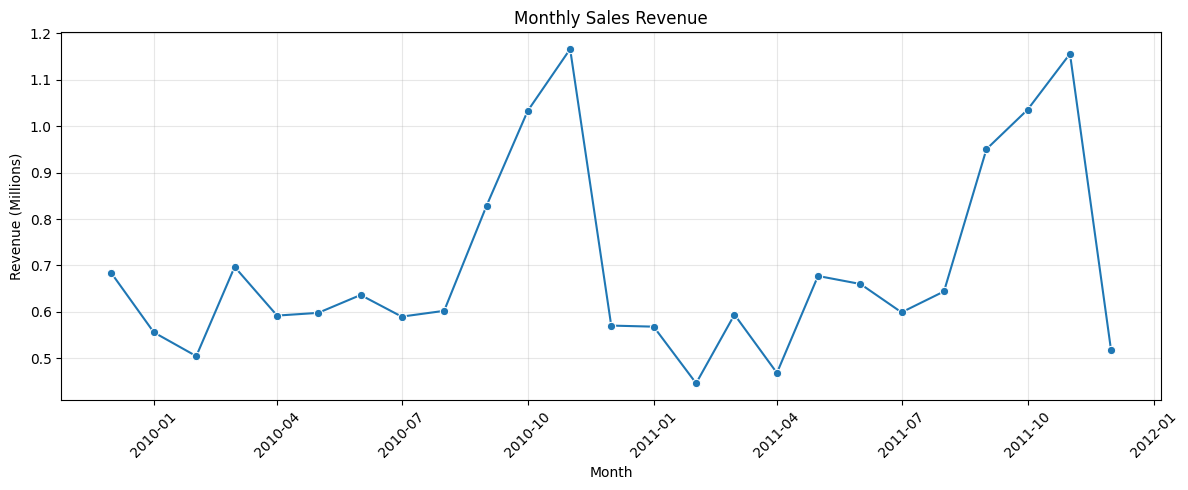

In [21]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Revenue_Millions",
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (Millions)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


- Seasonal pattern: Revenue increases strongly from September to November in both years, with the highest sales around November

- Lower sales: Revenue is generally lower in the first months of the year

- Business value: The company could use these patterns to plan inventory and marketing campaigns before the peak sales period

- Note: December 2011 contains only partial month data, so its revenue should not be directly compared with full months. The analysis also excludes returns and cancellations.

Calculate RFM
Recency: Days since last purchase (lower is better)
Frequency: Number of unique invoices
Monetary: Total positive sales revenue. The reference date is one day after the latest date in the dataset.

In [22]:
# Calculate the last date as one day after the last invoice date
last_date = clean["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", last_date)

Snapshot date: 2011-12-10 12:50:00


In [ ]:
#Create RFM table
rfm = clean.groupby("Customer ID").agg(     #Group by "Customer ID" and calculate the following metrics
    LastPurchase=("InvoiceDate", "max"),    #Last purchase date
    Frequency=("Invoice", "nunique"),       #Count unique invoices
    Monetary=("Revenue", "sum")             #Total revenue
).reset_index()
rfm.head()

,Customer ID,LastPurchase,Frequency,Monetary
0,12346.0,2011-01-18 10:01:00,12,77556.46
1,12347.0,2011-12-07 15:52:00,8,4921.53
2,12348.0,2011-09-25 13:13:00,5,2019.40
3,12349.0,2011-11-21 09:51:00,4,4428.69
4,12350.0,2011-02-02 16:01:00,1,334.40


In [ ]:
#Calculate how many days have passed since each customer’s last purchase
rfm["Recency"] = (last_date - rfm["LastPurchase"]).dt.days
rfm.head()

,Customer ID,LastPurchase,Frequency,Monetary,Recency
0,12346.0,2011-01-18 10:01:00,12,77556.46,326
1,12347.0,2011-12-07 15:52:00,8,4921.53,2
2,12348.0,2011-09-25 13:13:00,5,2019.40,75
3,12349.0,2011-11-21 09:51:00,4,4428.69,19
4,12350.0,2011-02-02 16:01:00,1,334.40,310


In [25]:
rfm = rfm[["Customer ID", "Recency", "Frequency", "Monetary"]]
rfm.head(10)

,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40
5,12351.0,375,1,300.93
6,12352.0,36,10,2849.84
7,12353.0,204,2,406.76
8,12354.0,232,1,1079.40
9,12355.0,214,2,947.61


In [26]:
print("Customers:", len(rfm))

Customers: 5878


In [ ]:
#Score Recency from 1 to 5 (5 = most recent)
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)

In [ ]:
#Score Frequency from 1 to 5 (5 = most frequent)
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

In [ ]:
#Score Monetary from 1 to 5 (5 = highest spending)
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

In [ ]:
#Combine R, F, and M scores into one label
rfm["RFM_Score"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)
#r cao khach mua gan day
#f cao khach mua nhieu lan

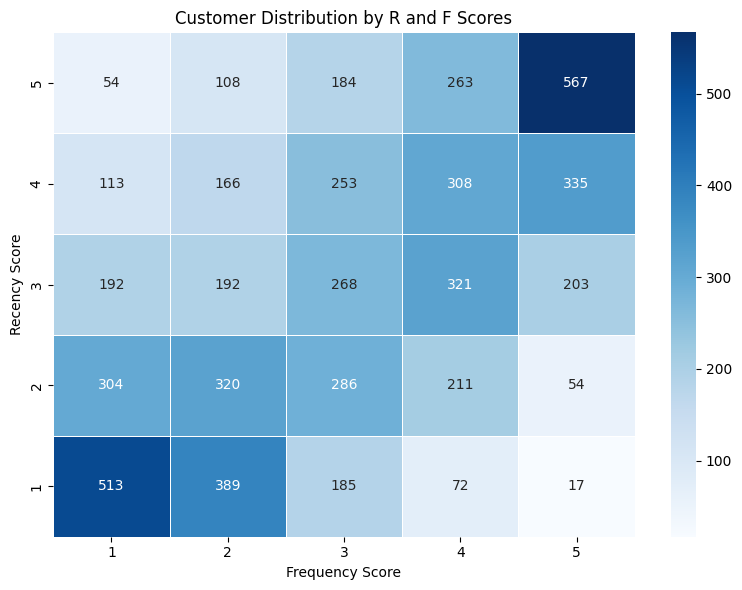

In [ ]:
#Count customers for each R-F score combination.
rf_counts = pd.crosstab(
    rfm["R_Score"],
    rfm["F_Score"]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    rf_counts.sort_index(ascending=False),
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Customer Distribution by R and F Scores")
plt.xlabel("Frequency Score")
plt.ylabel("Recency Score")
plt.tight_layout()
plt.show()

Customer Segmentation

The segmentation approach is inspired by the [RFM Segmentation Guide from Pushwoosh](https://docs.pushwoosh.com/product/audience-data-and-segmentation/segmentation/rfm-segmentation/).

Based on the R and F score distribution, customers are divided into six segments according to their purchasing behavior.

- Champions:Customers with the highest Recency and Frequency scores (R = 5, F = 5).
- Loyal Customers:Frequent buyers with medium to high Recency scores (R ≥ 3, F ≥ 4), excluding Champions.
- Recent Low Frequency:Recent buyers who purchase infrequently (R ≥ 4, F ≤ 2).
- At Risk:Customers who have not purchased recently but have purchased multiple times before (R ≤ 2, F ≥ 3).
- Inactive Customers: Customers with low Recency and Frequency scores (R ≤ 2, F ≤ 2).
- Other Customers: Customers who do not fit the above groups.


Monetary (M) is analyzed separately to compare customer spending across segments.

In [ ]:
#Assign customers to six segments based on R and F

def assign_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]

    if r == 5 and f == 5:
        return "Champions"
    elif r >= 3 and f >= 4:
        return "Loyal Customers"
    elif r >= 4 and f <= 2:
        return "Recent Low Frequency"
    elif r <= 2 and f >= 3:
        return "At Risk"
    elif r <= 2 and f <= 2:
        return "Inactive Customers"
    else:
        return "Other Customers"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

In [ ]:
#Count customers in each segment
segment_counts = rfm["Segment"].value_counts()
segment_counts

Segment
Inactive Customers      1526
Loyal Customers         1430
Other Customers         1089
At Risk                  825
Champions                567
Recent Low Frequency     441
Name: count, dtype: int64

In [ ]:
#Summarize customer behavior and revenue by segment
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Customer ID", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    TotalMonetary=("Monetary", "sum")
).sort_values("Customers", ascending=False)

segment_summary.round(2)

,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalMonetary
Segment,,,,,
Inactive Customers,1526,458.75,1.25,429.52,655444.68
Loyal Customers,1430,56.19,9.15,3759.56,5376170.31
Other Customers,1089,75.18,2.51,938.36,1021878.49
At Risk,825,368.88,4.94,1927.74,1590384.58
Champions,567,7.92,25.60,14707.39,8339087.94
Recent Low Frequency,441,27.97,1.46,888.52,391838.26


In [35]:
#Calculate revenue share by customer segment.
revenue_share = (
    segment_summary["TotalMonetary"]
    / segment_summary["TotalMonetary"].sum() * 100
).sort_values()

revenue_share

Segment
Recent Low Frequency     2.255210
Inactive Customers       3.772386
Other Customers          5.881381
At Risk                  9.153396
Loyal Customers         30.942336
Champions               47.995291
Name: TotalMonetary, dtype: float64

In [ ]:
#Calculate the percentage of customers in each segment
segment_summary["CustomerShare_%"] = (
    segment_summary["Customers"] /
    segment_summary["Customers"].sum() * 100
).round(1)

segment_summary

,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalMonetary,CustomerShare_%
Segment,,,,,,
Inactive Customers,1526,458.749672,1.252949,429.518140,655444.682,26.0
Loyal Customers,1430,56.190909,9.150350,3759.559655,5376170.306,24.3
Other Customers,1089,75.181818,2.509642,938.364090,1021878.494,18.5
At Risk,825,368.882424,4.941818,1927.738887,1590384.582,14.0
Champions,567,7.918871,25.604938,14707.386145,8339087.944,9.6
Recent Low Frequency,441,27.965986,1.460317,888.522132,391838.260,7.5


In [ ]:
#Calculate the percentage of revenue contributed by each segment
segment_summary["RevenueShare_%"] = (
    segment_summary["TotalMonetary"] /
    segment_summary["TotalMonetary"].sum() * 100
).round(1)
segment_summary

,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalMonetary,CustomerShare_%,RevenueShare_%
Segment,,,,,,,
Inactive Customers,1526,458.749672,1.252949,429.518140,655444.682,26.0,3.8
Loyal Customers,1430,56.190909,9.150350,3759.559655,5376170.306,24.3,30.9
Other Customers,1089,75.181818,2.509642,938.364090,1021878.494,18.5,5.9
At Risk,825,368.882424,4.941818,1927.738887,1590384.582,14.0,9.2
Champions,567,7.918871,25.604938,14707.386145,8339087.944,9.6,48.0
Recent Low Frequency,441,27.965986,1.460317,888.522132,391838.260,7.5,2.3


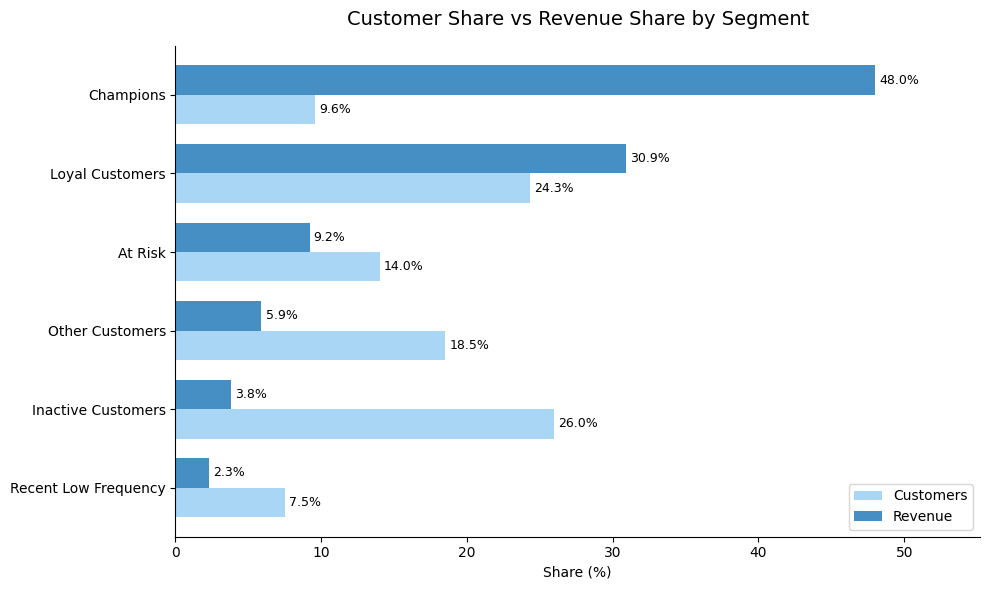

In [ ]:
#Compare customer share and revenue share.
comparison = segment_summary[
    ["CustomerShare_%", "RevenueShare_%"]
].sort_values("RevenueShare_%")

ax = comparison.plot(
    kind="barh",
    figsize=(10, 6),
    color=["#A9D6F5", "#468FC5"],
    width=0.75
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

plt.title("Customer Share vs Revenue Share by Segment", fontsize=14, pad=15)
plt.xlabel("Share (%)")
plt.ylabel("")
plt.legend(["Customers", "Revenue"], loc="lower right")


plt.xlim(0, comparison.max().max() * 1.15)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

- Champions represent only 9.6% of customers but contribute approximately 48% of total revenue.
- Loyal Customers contribute another 30.9% of revenue.
- Together, these two segments generate nearly 79% of revenue, showing that a relatively small share of customers accounts for most sales.